Dataset loaded successfully!
Dataset shape: (569, 30)
Target classes: ['malignant' 'benign']
Number of samples: 569

Training samples: 455
Testing samples: 114

Logistic Regression model trained successfully!

First 10 actual values:    [0 1 0 1 0 1 1 0 0 0]
First 10 predicted values: [0 1 0 1 0 1 1 0 0 0]

========== MODEL EVALUATION ==========
Accuracy  : 0.9825
Precision : 0.9861
Recall    : 0.9861
F1-Score  : 0.9861

Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

Confusion Matrix:
[[41  1]
 [ 1 71]]


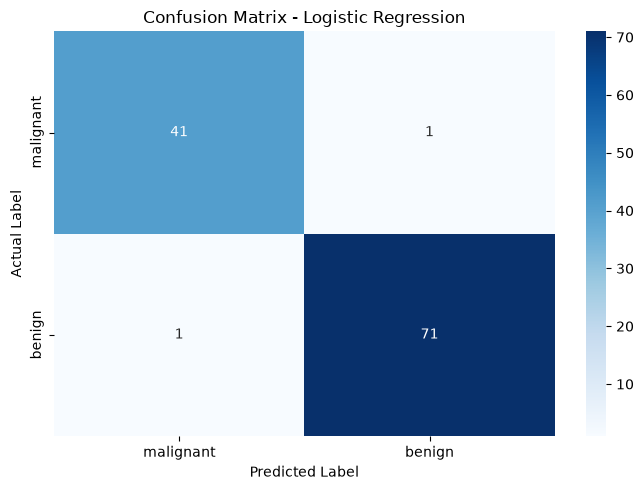

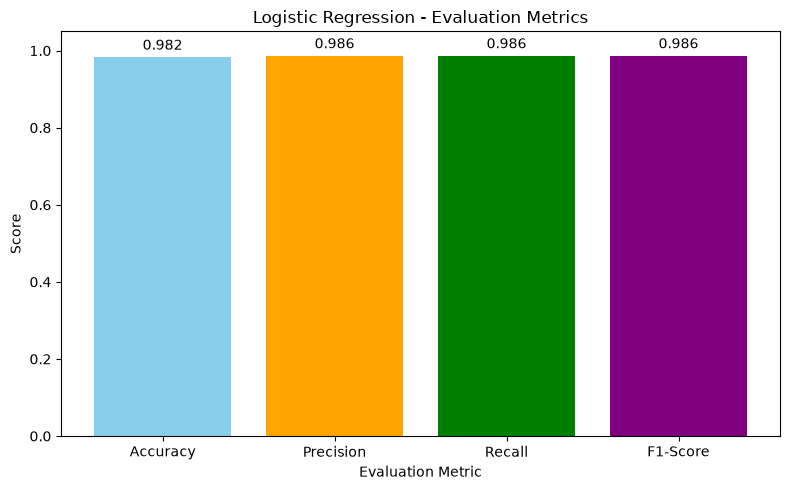

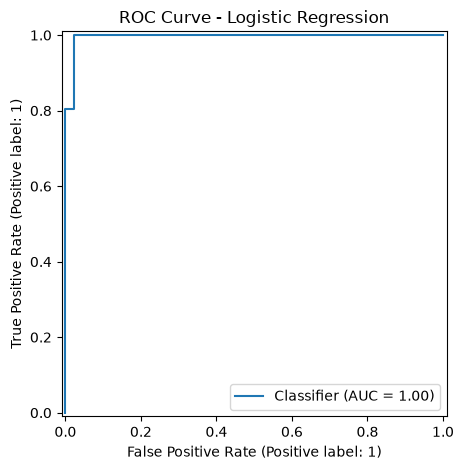

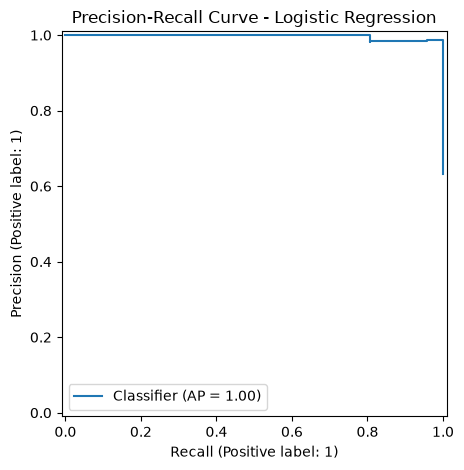

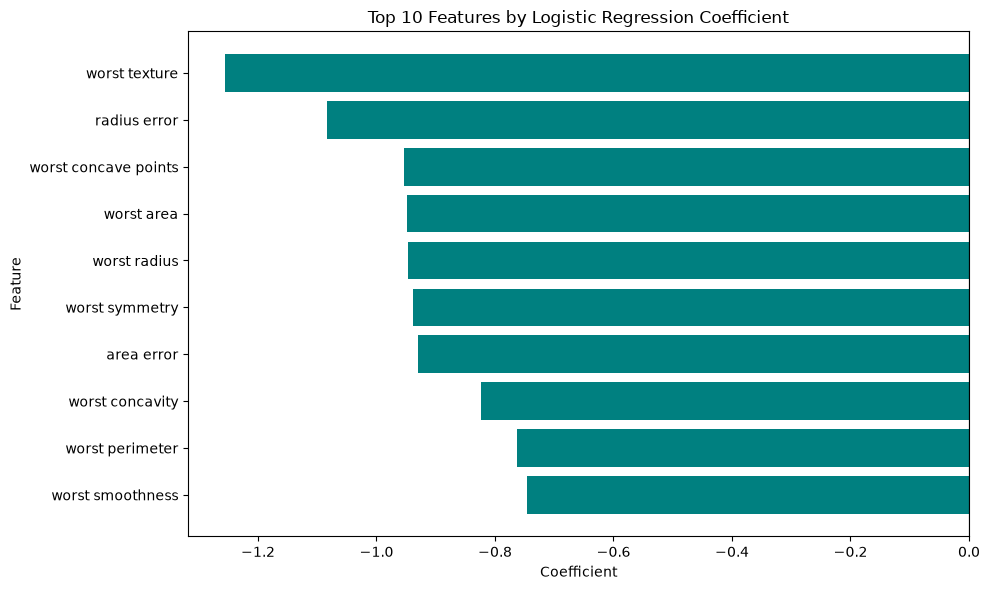


Lab 8 completed successfully!


In [5]:

# LAB 8: LOGISTIC REGRESSION FOR BINARY CLASSIFICATION
# Aim: Build a Logistic Regression model and evaluate it using
# Confusion Matrix, Precision, Recall, F1-Score and graphs.

# Step 1: Import required libraries
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

# Step 2: Load the dataset
data = load_breast_cancer()
X = data.data
y = data.target

print("Dataset loaded successfully!")
print("Dataset shape:", X.shape)
print("Target classes:", data.target_names)
print("Number of samples:", len(y))

# Step 3: Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

# Step 4: Create and train the Logistic Regression model
# Scaling is fitted only on training data through the pipeline.
model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(max_iter=5000))
])

model.fit(X_train, y_train)
print("\nLogistic Regression model trained successfully!")

# Step 5: Make predictions
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("\nFirst 10 actual values:   ", y_test[:10])
print("First 10 predicted values:", y_pred[:10])

# Step 6: Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("\n========== MODEL EVALUATION ==========")
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=data.target_names,
    zero_division=0
))

# Step 7: Display the confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=data.target_names,
    yticklabels=data.target_names
)
plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

# Step 8: Plot the evaluation metrics
metrics = {
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1-Score": f1
}

plt.figure(figsize=(8, 5))
bars = plt.bar(
    metrics.keys(),
    metrics.values(),
    color=["skyblue", "orange", "green", "purple"]
)
plt.ylim(0, 1.05)
plt.title("Logistic Regression - Evaluation Metrics")
plt.ylabel("Score")
plt.xlabel("Evaluation Metric")

for bar, score in zip(bars, metrics.values()):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.02,
        f"{score:.3f}",
        ha="center"
    )

plt.tight_layout()
plt.show()

# Step 9: Plot the ROC curve
RocCurveDisplay.from_predictions(y_test, y_prob)
plt.title("ROC Curve - Logistic Regression")
plt.tight_layout()
plt.show()

# Step 10: Plot the Precision-Recall curve
PrecisionRecallDisplay.from_predictions(y_test, y_prob)
plt.title("Precision-Recall Curve - Logistic Regression")
plt.tight_layout()
plt.show()

# Step 11: Plot the most influential features
coefficients = model.named_steps["logistic"].coef_[0]
feature_names = data.feature_names

top_indices = np.argsort(np.abs(coefficients))[-10:]
top_indices = top_indices[np.argsort(np.abs(coefficients[top_indices]))]

plt.figure(figsize=(10, 6))
plt.barh(
    feature_names[top_indices],
    coefficients[top_indices],
    color="teal"
)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Top 10 Features by Logistic Regression Coefficient")
plt.xlabel("Coefficient")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

print("\nLab 8 completed successfully!")



In [8]:
import pandas as pd

df = pd.read_csv("Colleges_Dataset.csv")

print("Column names:")
print(df.columns.tolist())

print("\nUnique values in each column:")
for col in df.columns:
    print(f"\n{col}: {df[col].nunique()} unique values")
    print(df[col].unique()[:10])

Column names:
['Unnamed: 0', 'College_Name', 'State', 'UG_fee', 'PG_fee', 'Rating', 'Academic', 'Accommodation', 'Faculty', 'Infrastructure', 'Placement', 'Social_Life']

Unique values in each column:

Unnamed: 0: 732 unique values
[0 1 2 3 4 5 6 7 8 9]

College_Name: 631 unique values
<StringArray>
[  'Indian Institute of Technology Madras ',
 'College of Engineering, Anna University ',
             'NIT Trichy, Tiruchirappalli ',
         'Vellore Institute of Technology ',
    'SRM Engineering College, Kanchipuram ',
              'SSN College of Engineering ',
            'SASTRA University, Thanjavur ',
             'P.S.G College of Technology ',
      'Thiagarajar College of Engineering ',
      'Coimbatore Institute of Technology ']
Length: 10, dtype: str

State: 35 unique values
<StringArray>
[    'Tamil nadu',    'Maharashtra',  'Uttar pradesh',      'Delhi ncr',
 'Andhra pradesh',      'Karnataka',      'Telangana', 'Madhya pradesh',
         'Kerala',      'Rajasthan']
Leng

First 5 rows:
   Unnamed: 0                              College_Name       State    UG_fee  \
0           0    Indian Institute of Technology Madras   Tamil nadu     75116   
1           1  College of Engineering, Anna University   Tamil nadu     50000   
2           2              NIT Trichy, Tiruchirappalli   Tamil nadu  1,49,250   
3           3          Vellore Institute of Technology   Tamil nadu  1,98,000   
4           4     SRM Engineering College, Kanchipuram   Tamil nadu  2,60,000   

     PG_fee Rating Academic Accommodation Faculty Infrastructure Placement  \
0     23070    8.7        9           7.9     8.7            8.8       8.8   
1     50000    8.4      8.7           7.7     8.1            8.7       8.3   
2     99250    8.5      8.6           7.8     8.2            8.7       8.8   
3  1,83,000    8.3      8.3             8     7.8            8.9       8.5   
4  1,70,000    7.2      6.5           6.6     6.9            7.6       7.1   

  Social_Life  
0           9 

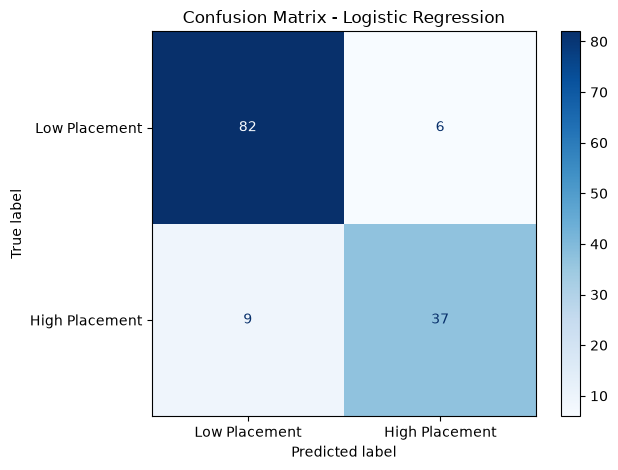

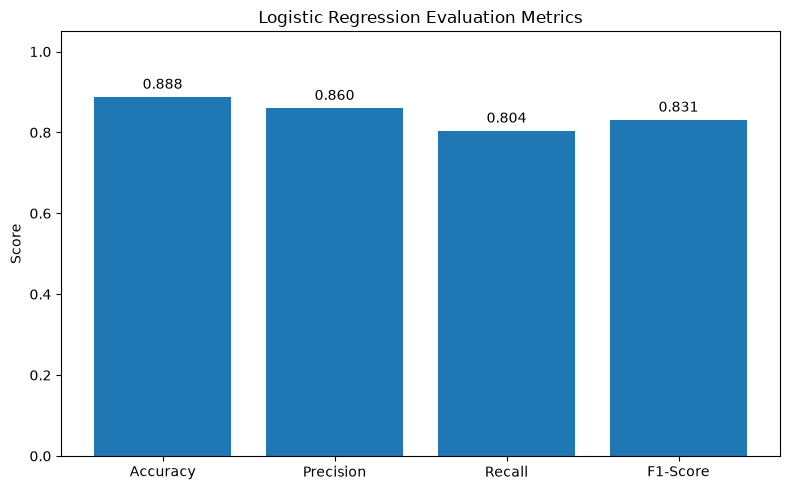

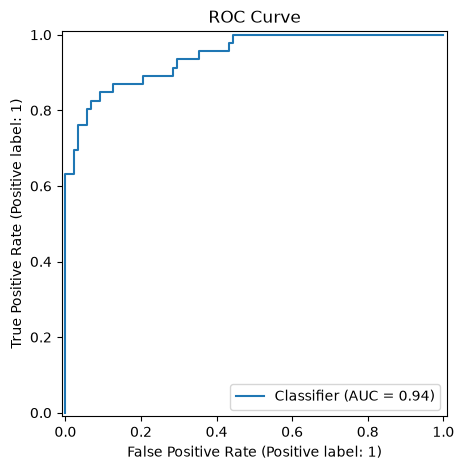

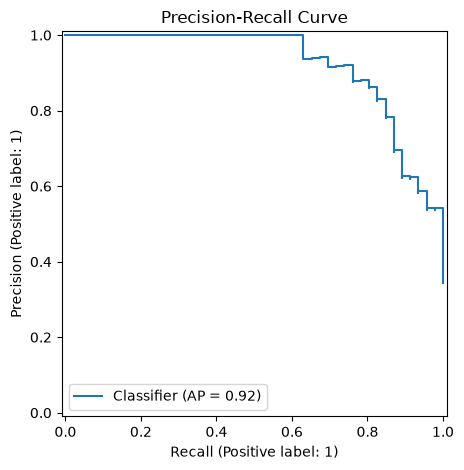

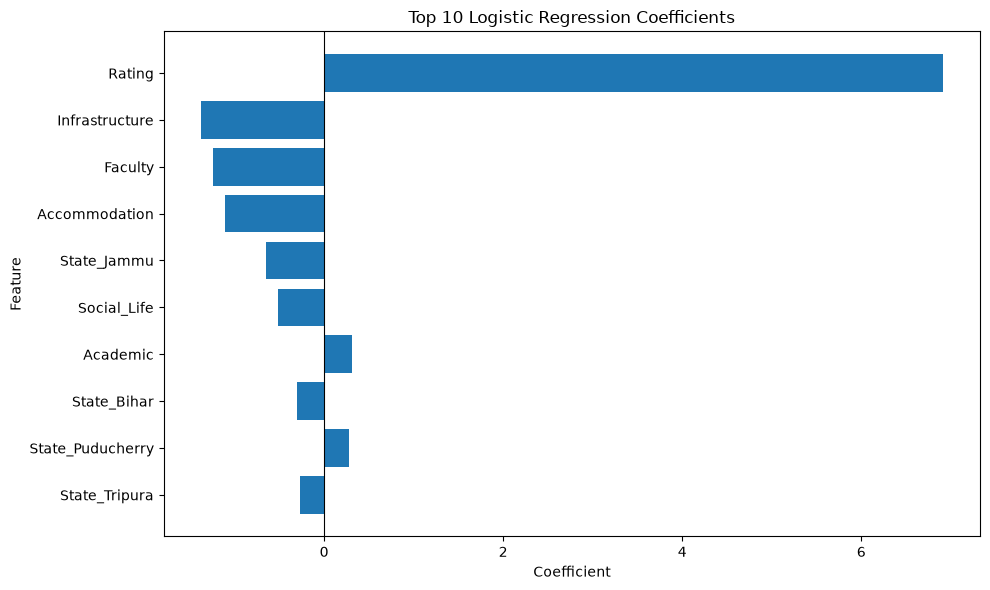


Lab 8 completed successfully!


In [10]:

# ============================================================
# LAB 8: LOGISTIC REGRESSION FOR BINARY CLASSIFICATION
# Dataset: Colleges_Dataset.csv
# ============================================================

# Step 1: Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

# Step 2: Load dataset
df = pd.read_csv("Colleges_Dataset.csv")

print("First 5 rows:")
print(df.head())

print("\nDataset shape:", df.shape)
print("\nColumns:", df.columns.tolist())

# Step 3: Clean numeric columns
# Convert fees and ratings to numbers.
# Commas are removed from fees; '--' becomes missing.
for col in ["UG_fee", "PG_fee", "Rating", "Academic",
            "Accommodation", "Faculty", "Infrastructure",
            "Placement", "Social_Life"]:
    df[col] = pd.to_numeric(
        df[col].astype(str).str.replace(",", "", regex=False)
          .replace("--", np.nan),
        errors="coerce"
    )

# Step 4: Create a binary target from Placement rating
# 1 = High Placement (rating >= 8)
# 0 = Low Placement (rating < 8)
df = df.dropna(subset=["Placement"]).copy()

df["Placement_Status"] = (
    df["Placement"] >= 8.0
).astype(int)

print("\nPlacement class counts:")
print(df["Placement_Status"].value_counts())
print("0 = Low Placement; 1 = High Placement")

# Step 5: Select features and target
# Exclude identifiers, names, original Placement rating,
# and the derived target to avoid data leakage.
X = df.drop(columns=[
    "Unnamed: 0",
    "College_Name",
    "Placement",
    "Placement_Status"
], errors="ignore")

y = df["Placement_Status"]

# Encode categorical columns such as State
X = pd.get_dummies(X, columns=["State"], drop_first=True,
                   dtype=int)

# Fill missing numeric values with column medians
X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median())

print("\nFeatures shape:", X.shape)
print("Target shape:", y.shape)

# Step 6: Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

# Step 7: Build and train Logistic Regression
model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(max_iter=2000))
])

model.fit(X_train, y_train)

print("\nModel trained successfully!")

# Step 8: Make predictions
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# Step 9: Evaluate model
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("\n===== MODEL EVALUATION =====")
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    labels=[0, 1],
    target_names=["Low Placement", "High Placement"],
    zero_division=0
))

# Step 10: Confusion Matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print("Confusion Matrix:\n", cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Low Placement", "High Placement"]
)
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix - Logistic Regression")
plt.tight_layout()
plt.show()

# Step 11: Evaluation metrics bar chart
metrics = {
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1-Score": f1
}

plt.figure(figsize=(8, 5))
bars = plt.bar(metrics.keys(), metrics.values())

plt.ylim(0, 1.05)
plt.ylabel("Score")
plt.title("Logistic Regression Evaluation Metrics")

for bar, value in zip(bars, metrics.values()):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.02,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()
plt.show()

# Step 12: ROC curve
RocCurveDisplay.from_predictions(y_test, y_prob)
plt.title("ROC Curve")
plt.tight_layout()
plt.show()

# Step 13: Precision-Recall curve
PrecisionRecallDisplay.from_predictions(y_test, y_prob)
plt.title("Precision-Recall Curve")
plt.tight_layout()
plt.show()

# Step 14: Feature coefficient graph
coefficients = model.named_steps["logistic"].coef_[0]

top_indices = np.argsort(np.abs(coefficients))[-10:]
top_indices = top_indices[
    np.argsort(np.abs(coefficients[top_indices]))
]

plt.figure(figsize=(10, 6))
plt.barh(
    X.columns[top_indices],
    coefficients[top_indices]
)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Coefficient")
plt.ylabel("Feature")
plt.title("Top 10 Logistic Regression Coefficients")
plt.tight_layout()
plt.show()

print("\nLab 8 completed successfully!")
